# Setup

Making sure the right python version is being used, because Python 3.7 or above is required for this project:

In [50]:
import sys

assert sys.version_info >= (3, 7)

Making sure the right Scikit-Learn version is being used, because Scikit-Learn 1.0.1 or above is required for this project:

In [51]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

importting the main libraries used in this project, includin pandas and numpy for data handlin, matplotlib and seaborn for visualisation, and other tools for machine learning.

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split

# Getting the Data for the house price file

Welcome to Assignment 1 for Introduction to Atrifical Intelligence Module. My task is to analyse the sales data of a large US based estate and improve their business operations using machine learning. My task includes cleaning up the given dataset, visualising critical information, and developing solutions using techniques learned from this module.

## Downloading the Data

In [53]:
houseprice_raw = pd.read_csv('As1datasets/houseprice.csv') #reading the dataset
original_df2 = houseprice_raw.copy() #keeping a copy of the original dataset

## Taking a Quick Look at the Data Structure

In [54]:
houseprice_raw.head()

,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Address,City,State,Zipcode,Address Full
0,"$895,900","3,447 sqft",-112.081985,33.560055,"7,895 sqft",4.0,4.5,2019.0,NaN,NaN,"630 W Echo Ln Phoenix, AZ 85021",Phoenix,AZ,85021.0,"630 W Echo Ln, Phoenix, AZ 85021"
1,"$247,000","1,767 sqft",-96.676250,32.829227,"7,877 sqft",3.0,2.0,1954.0,NaN,NaN,"2367 Highwood Dr Dallas, TX 75228",Dallas,TX,75228.0,"2367 Highwood Dr, Dallas, TX 75228"
2,"$44,900","1,232 sqft",-78.825190,42.913000,"3,510 sqft",3.0,1.0,1900.0,NaN,NaN,"30 Hurlock Ave Buffalo, NY 14211",Buffalo,NY,14211.0,"30 Hurlock Ave, Buffalo, NY 14211"
3,"$959,000","1,417 sqft",-73.860170,40.722960,"2,598 sqft",3.0,2.0,1939.0,2009.0,"$532,000","6416 Alderton St Flushing, NY 11374",Flushing,NY,11374.0,"6416 Alderton St, Flushing, NY 11374"
4,"$83,500",440 sqft,-80.206314,25.937965,NaN,NaN,1.0,1971.0,2007.0,"$52,000","251 NW 177th St #A-123 Miami Gardens, FL 33169",Miami Gardens,FL,33169.0,"251 NW 177th St #A-123, Miami Gardens, FL 33169"


In [55]:
houseprice_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30006 entries, 0 to 30005
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Price           30006 non-null  object 
 1   Sqr Ft          27786 non-null  object 
 2   Longitude       30006 non-null  float64
 3   Latitude        30006 non-null  float64
 4   Lot Size        25490 non-null  object 
 5   Beds            27420 non-null  float64
 6   Bath            27496 non-null  float64
 7   Year Built      26258 non-null  float64
 8   Last Sold Year  14213 non-null  float64
 9   Last Sold For   14213 non-null  object 
 10  Address         30006 non-null  object 
 11  City            30006 non-null  object 
 12  State           30006 non-null  object 
 13  Zipcode         30003 non-null  float64
 14  Address Full    30006 non-null  object 
dtypes: float64(7), object(8)
memory usage: 3.4+ MB


In [56]:
houseprice_raw["Last Sold For"].value_counts()

Last Sold For
$125,000      88
$175,000      82
$250,000      81
$150,000      81
$130,000      77
              ..
$53,947        1
$247,272       1
$193,697       1
$606,600       1
$5,500,000     1
Name: count, Length: 3868, dtype: int64

In [57]:
houseprice_raw.describe()

,Longitude,Latitude,Beds,Bath,Year Built,Last Sold Year,Zipcode
count,30006.000000,30006.000000,27420.000000,27496.000000,26258.000000,14213.000000,30003.000000
mean,-95.167341,36.158007,3.288658,2.578688,1973.140224,2011.110673,59349.268440
std,15.454027,5.500075,1.472238,1.448891,34.512400,6.596002,27206.130444
min,-150.047160,25.550295,1.000000,0.750000,1800.000000,1987.000000,2108.000000
25%,-106.742751,32.747084,3.000000,2.000000,1950.000000,2006.000000,33137.000000
50%,-93.390977,36.016481,3.000000,2.000000,1978.000000,2013.000000,68124.000000
75%,-81.638904,40.017658,4.000000,3.000000,2004.000000,2017.000000,85016.000000
max,-70.997740,61.442024,65.000000,98.000000,2019.000000,2019.000000,99587.000000


The following cell creates the `images/end_to_end_project` folder (if it doesn't already exist), and it defines the `save_fig()` function to save the figures in high-res

In [58]:
#setting up a folder to save the images
IMAGES_PATH = Path() / "As1images" / "data_exploration" #appends images to the folder, and appends data_exploration as its subfolder
IMAGES_PATH.mkdir(parents=True, exist_ok=True) #creates the folder if it does not already exist

#function for saving figures to the As1images folder as high-res PNGs
def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300): #creating a function to save the figures
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout: #if it has a tight layout then do the follwoing
        #using tight_layout to automatically adjust the padding so axis labels don't get cut off
        plt.tight_layout()
    #saving the image
    plt.savefig(path, format=fig_extension, dpi=resolution) #saving the figure in the images folder

The following cell contains code for setting the the default font sizes

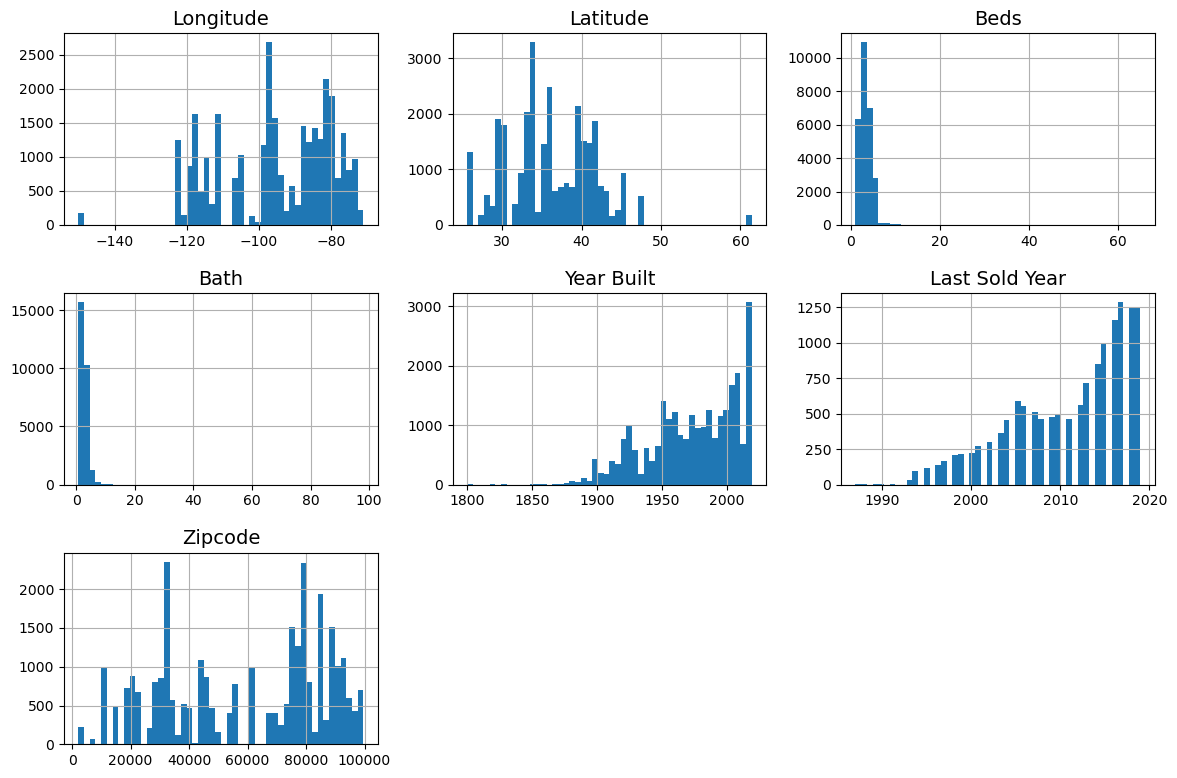

In [59]:
#code for the default font sizes
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

houseprice_raw.hist(bins=50, figsize=(12, 8))
save_fig("attribute_histogram_plots") #giving it a "fig_id = attribute_histogram_plots", and saving the figure in the images folder
plt.show()

I started by spending some time to explore and the date, and then visulaize it. These were the first steps I have done.

# Data Cleaning

In [60]:
import pandas as pd
from sklearn.impute import SimpleImputer

def clean_housing_data(houseprice_raw):
    #creating a copy to avoid changing the original raw data
    df_clean = houseprice_raw.copy()
    
    #dropping duplicates
    df_clean = df_clean.drop_duplicates()
    
    #dropping rows where Price is missing
    df_clean = df_clean.dropna(subset=['Price'])

    if 'Lot Size' in df_clean.columns:
        #detecting which rows contain acre
        is_acres = df_clean['Lot Size'].astype(str).str.contains('acre', case=False, na=False)
        
        #removing commas and extracting just the numbers/decimals
        df_clean['Lot Size'] = df_clean['Lot Size'].astype(str).str.replace(r'[a-zA-Z, ]', '', regex=True).str.strip()
        df_clean['Lot Size'] = pd.to_numeric(df_clean['Lot Size'], errors='coerce')
        
        #multiplying the rows with acres by 43,560 to convert acres to square feet
        df_clean.loc[is_acres, 'Lot Size'] *= 43560
    
    #cleaning columns by Removing $, commas, and text in the following columns: Price, Last Sold For, Sqr Ft, Lot Size
    cols_to_clean = ['Price', 'Last Sold For', 'Sqr Ft', 'Lot Size']
    for col in cols_to_clean:
        if col in df_clean.columns:
            # Removing letters, commas, and symbols
            df_clean[col] = df_clean[col].astype(str).str.replace(r'[a-zA-Z,$\+ ]', '', regex=True).str.strip()
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

    #filling missing Sqr Ft based on the median of the City
    if 'Sqr Ft' in df_clean.columns and 'City' in df_clean.columns:
        df_clean['Sqr Ft'] = df_clean.groupby('City')['Sqr Ft'].transform(
            lambda x: x.fillna(x.median())
        )
        #and if there are still rows that have a missing Sqr Ft(for example, a city had no Sqr Ft data at all), then we would fill the Sqr Ft of that city with a global median
        df_clean['Sqr Ft'] = df_clean['Sqr Ft'].fillna(df_clean['Sqr Ft'].median())
        
    #removing Outliers using the IQR Method for Price. startign first by calculating the upper and lower Quartiles
    Q1 = df_clean['Price'].quantile(0.25)
    Q3 = df_clean['Price'].quantile(0.75)
    #calucating the Interquartile range
    IQR = Q3 - Q1
    
    #defining the bounds according to the standard statistical threshold (1.5 * IQR is the standard statistical threshold)
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    #keeping only the rows that are within the bounds
    df_clean = df_clean[(df_clean['Price'] >= lower_bound) & (df_clean['Price'] <= upper_bound)]
    
    #grouping the columns that has continuous numerical data together because it makes sense to get their average for example size, and for example number of rooms)
    numeric_columns = ["Sqr Ft", "Lot Size", "Beds", "Bath", "Year Built"]

    #gruping the columns that are Categorical and has discrete data together, because I do not need to get the average of a zipcode, because it wouldn't make sense
    categorical_columns = ["Last Sold Year", "Zipcode", "Last Sold For"]

    #filling missing values using SimpleImputer, and using 'mean' for continuous numbers and 'most_frequent' for categorical/discrete data, so separating the columns into two lists based on their data type and how to handle them
    #so for numerical columns, filling missing values (NaNs) with the mathematical average (mean) of that column
    numeric_imputer = SimpleImputer(strategy="mean")
    #and for categorical columns, filling missing values with the most common value (mode) found in that column
    categorical_imputer = SimpleImputer(strategy="most_frequent")

    #calculating the mean for each numerical column and instantly replacing the missing values in the dataframe
    df_clean[numeric_columns] = numeric_imputer.fit_transform(df_clean[numeric_columns])

    #calculating the most frequent value for each categorical column and instantly replacing the missing values
    df_clean[categorical_columns] = categorical_imputer.fit_transform(df_clean[categorical_columns])
    
    return df_clean

In [61]:
#running the houseprice dataset cleaning function, and storing the cleaned data in the variable cleaned_houseprice
cleaned_houseprice = clean_housing_data(houseprice_raw)

In [62]:
#exporting the cleaned data to a new CSV file without the index column
cleaned_houseprice.to_csv("my_cleaned_houseprice.csv", index=False)

print(f"the cleaned_houseprice has {len(cleaned_houseprice)} rows")

the cleaned_houseprice has 27136 rows


In [63]:
#taking a look at the data to confirm that count for each row is 27136 (2.713600e+04 is equal to 27136 )
cleaned_houseprice.describe()

,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Zipcode
count,2.713600e+04,2.713600e+04,27136.000000,27136.000000,2.713600e+04,27136.000000,27136.000000,27136.000000,27136.000000,2.713600e+04,27136.000000
mean,3.356991e+05,3.932841e+03,-94.797724,36.178851,9.319972e+04,3.188282,2.402090,1973.454961,2015.302513,1.823437e+05,59123.504275
std,2.211778e+05,2.192503e+05,15.031196,5.533689,4.742608e+06,1.181565,0.954944,31.674698,5.981218,7.440439e+05,26586.056509
min,1.000000e+00,1.000000e+00,-150.047160,25.550295,1.000000e+00,1.000000,0.750000,1800.000000,1989.000000,1.000000e+00,2110.000000
25%,1.750000e+05,1.289000e+03,-106.227594,32.714501,5.066000e+03,3.000000,2.000000,1954.000000,2014.000000,1.250000e+05,33143.000000
50%,2.850000e+05,1.761000e+03,-93.306225,36.030698,8.276000e+03,3.000000,2.000000,1973.454961,2019.000000,1.250000e+05,67216.500000
75%,4.499000e+05,2.348000e+03,-81.699280,40.010700,2.570040e+04,4.000000,3.000000,2001.000000,2019.000000,1.785000e+05,80904.000000
max,1.059000e+06,3.600380e+07,-70.997740,61.442024,5.502665e+08,64.000000,17.000000,2019.000000,2019.000000,1.200000e+08,99577.000000


After looking at the data again I found out that I need to add filters to the dataset becuase I noticed the maximum number of beds is 64, and it does not common to have a house that has 64 beds. Properties with 64 beds are not likely to be standard residential homes, and they could be hostels, hotels, or commercial estates. However, since in some rare cases some luxiourious residential homes can legally have this number of bedrooms. I have decided to stick to houses that have 15 or less bedrooms, as hostels can start with 16 or more bedrooms. Also, I noticed that I have a $1 house price, which is logically impossible. 

In [64]:
copy_cleaned = pd.read_csv('my_cleaned_houseprice.csv') #reading the cleaned dataset
houseprice_filtered = copy_cleaned.copy()

In [65]:
#creating a new, filtered dataframe by applying logical conditions
houseprice_filtered = copy_cleaned[
    #a house must have 15 or fewer beds and a price must be at least $10,000 
    (copy_cleaned['Beds'] <= 15) & (copy_cleaned['Price'] >= 10000)
]

#printting out how many rows we removed to clean up the data
rows_removed = len(copy_cleaned) - len(houseprice_filtered)
print(f"Removed {rows_removed} extreme outlier rows.")
print(f"Remaining clean data: {len(houseprice_filtered)} houses.")

#overwriting the cleaned dataframe with the dataframe thatt has beenn cleaned and has been filtered
housePrice_cleaned = houseprice_filtered.copy()

Removed 203 extreme outlier rows.
Remaining clean data: 26933 houses.


In [66]:
#taking a look at the data to confirm that count for each row is 26933 (2.693300e+04 is equal to 26933 )
housePrice_cleaned.describe()

,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Zipcode
count,2.693300e+04,2.693300e+04,26933.000000,26933.000000,2.693300e+04,26933.000000,26933.000000,26933.000000,26933.000000,2.693300e+04,26933.000000
mean,3.381989e+05,3.951417e+03,-94.859704,36.153204,9.377979e+04,3.184125,2.406740,1973.698750,2015.310437,1.830563e+05,59196.727658
std,2.201201e+05,2.200749e+05,15.052884,5.535346,4.760441e+06,1.061709,0.955314,31.584563,5.976815,7.467657e+05,26635.204959
min,1.000000e+04,1.000000e+00,-150.047160,25.550295,1.000000e+00,1.000000,0.750000,1800.000000,1989.000000,1.000000e+01,2110.000000
25%,1.790000e+05,1.292000e+03,-106.252110,32.707630,5.120000e+03,3.000000,2.000000,1955.000000,2014.000000,1.250000e+05,33141.000000
50%,2.890000e+05,1.764000e+03,-93.337780,36.022774,8.276000e+03,3.000000,2.000000,1973.454961,2019.000000,1.250000e+05,68022.000000
75%,4.499000e+05,2.353000e+03,-81.693680,39.989925,2.613600e+04,4.000000,3.000000,2001.000000,2019.000000,1.800000e+05,80906.000000
max,1.059000e+06,3.600380e+07,-70.997740,61.442024,5.502665e+08,15.000000,17.000000,2019.000000,2019.000000,1.200000e+08,99577.000000


In [67]:
#exporting the cleaned filtered data to a new CSV file without the index column
housePrice_cleaned.to_csv("my_cleaned_filtered_houseprice.csv", index=False)

After cleaning the houseprice dataset using a cleaning function and filtering to remove extreme outliers, I want to see the correlation between the columns of the dataset through a heatmap

# Data Exploration

## Correlation

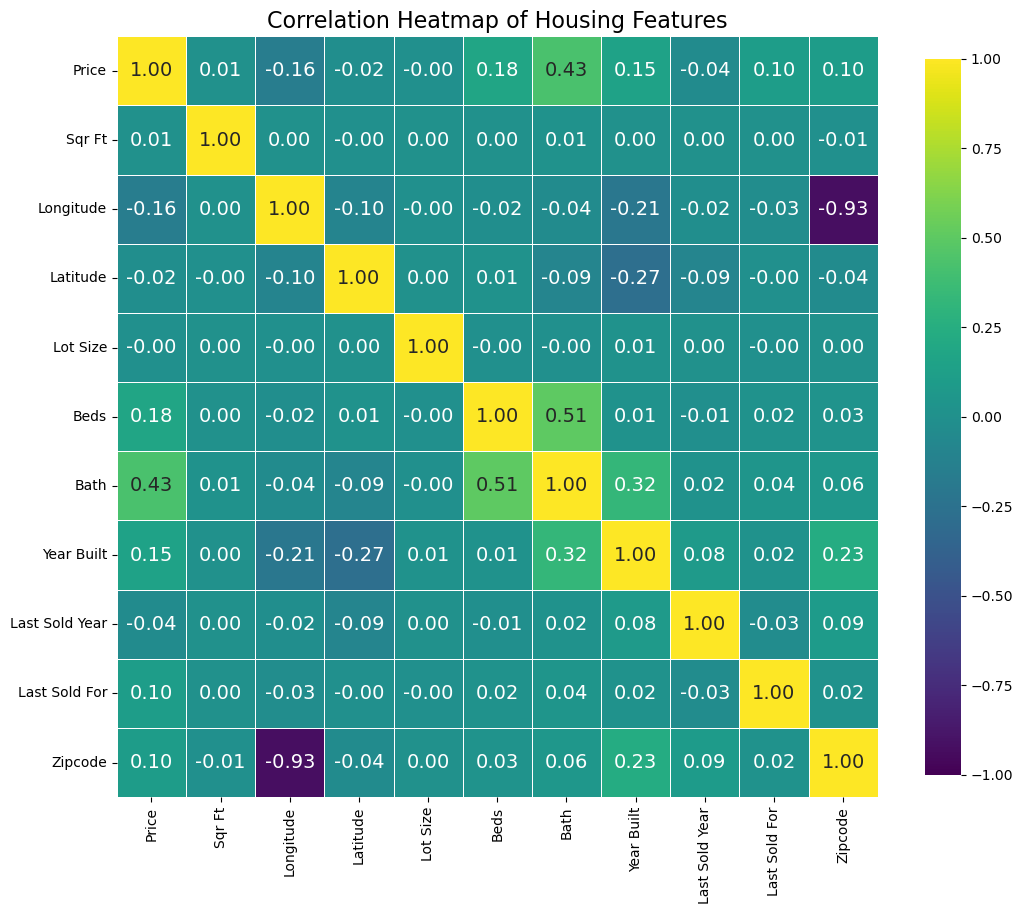

In [68]:
numerical_cols = cleaned_houseprice.select_dtypes(include=[np.number]).columns

#calculating the correlation matrix
corr_matrix = cleaned_houseprice[numerical_cols].corr()

#creating a geometric mask to hide the top right triangle, and that's to remove duplicate data

#setting up the figure size
plt.figure(figsize=(11, 10))

#drawing the heatmap
sns.heatmap(corr_matrix, cmap='viridis', vmax=1.0, vmin=-1.0, center=0, square=True, linewidths=.5, annot=True, fmt='.2f', cbar_kws={"shrink": .8})

plt.title('Correlation Heatmap of Housing Features', fontsize=16)
#saving the figure using the save_fig function
save_fig("correlation_heatmap")
#displaying the plot
plt.show()

### Looking at the price column on heatmap, I can see that:
#### bath and price have a positive relationship +0.43, 
#### and price and beds have a positive relationship of +0.18, 
#### and price and year built have a positive relationship of +0.15, 
#### and price and longitude have a negative relationship of -0.16, 
#### and price and last year sold have a negative relationship of -0.04.

Based on the correlation heatmap, I can understand that as the number of bathrooms goes up, the price is likely to go up. I can also see two other positive relationships and one negative that are not as strong as the number of bathrooms, but still can help predict the house price, and those three predictors are the Longitude, numbers of beds, and the the year built of the house. so while the number of bathrooms is a solid indicator of a property's value, features like the Longitude, the year it was built, or the number of bedrooms are too inconsistent to predict price reliably on their own

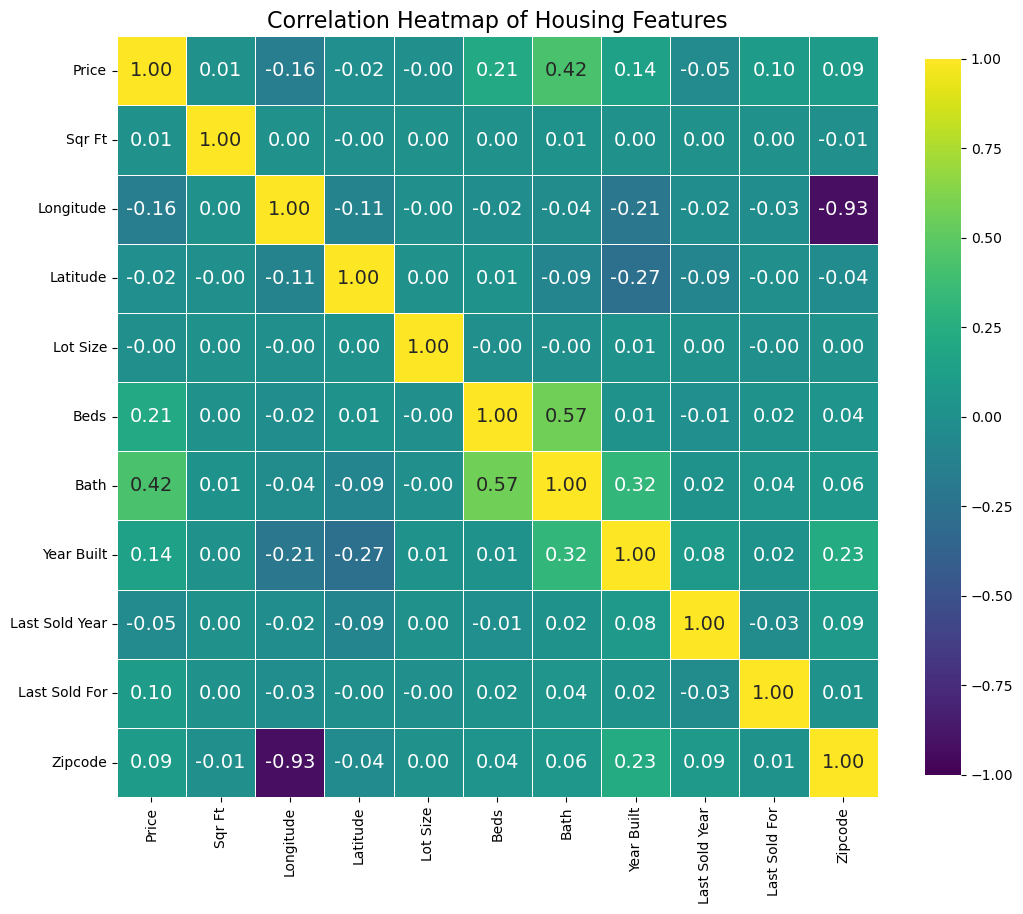

In [69]:
#selecting the numerical columns
numerical_cols = housePrice_cleaned.select_dtypes(include=[np.number]).columns

#calculating the correlation matrix
corr_matrix = housePrice_cleaned[numerical_cols].corr()

#creating a geometric mask to hide the top right triangle, and that's to remove duplicate data

#setting up the figure size
plt.figure(figsize=(11, 10))

#drawing the heatmap
sns.heatmap(corr_matrix, cmap='viridis', vmax=1.0, vmin=-1.0, center=0, square=True, linewidths=.5, annot=True, fmt='.2f', cbar_kws={"shrink": .8})

plt.title('Correlation Heatmap of Housing Features', fontsize=16)
#saving the figure using the save_fig function
save_fig("correlation_heatmap_filteredData")
#displaying the plot
plt.show()

### Looking at the price column on heatmap, I can see that:
#### bath and price have a positive relationship +0.42, 
#### and price and beds have a positive relationship of +0.21, 
#### and price and year built have a positive relationship of +0.14, 
#### and price and longitude have a negative relationship of -0.16, 
#### and price and last year sold have a negative relationship of -0.04.

Based on the correlation heatmap on the filtered data, where data have been cleaned of extreme outliners in the beds column. I can confirm that as the number of bathrooms goes up, the price to go up. The correlation matrix confirms that the number of bathrooms (0.42) and bedrooms (0.21) are the most reliable indicators of property value, indicating that room count is a critical selling point in this specific market

In [70]:
#calculating the correlation matrix for numeric columns
correlation_matrix = housePrice_cleaned.corr(numeric_only=True)
#printing how strongly each feature correlates with the Price column
print(correlation_matrix['Price'].sort_values(ascending=False))

Price             1.000000
Bath              0.423988
Beds              0.206163
Year Built        0.141493
Last Sold For     0.101091
Zipcode           0.094708
Sqr Ft            0.005138
Lot Size         -0.004169
Latitude         -0.015047
Last Sold Year   -0.047586
Longitude        -0.159253
Name: Price, dtype: float64


## Scatter Plots

### Price and Number of bathrooms

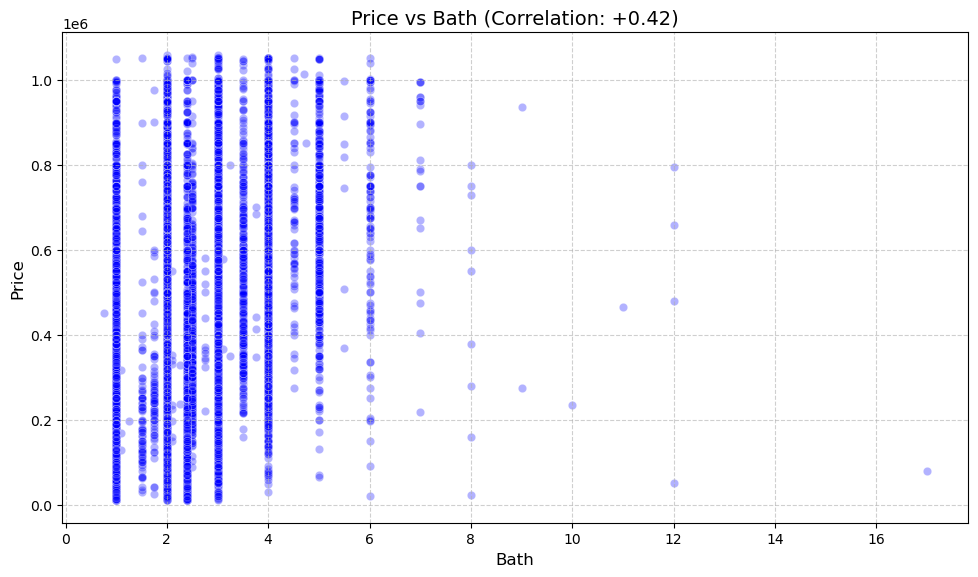

In [71]:
#plotting the relationship between price and number of bathrroms
plt.figure(figsize=(10, 6))
#using alpha=0.3 to make the overlappin points darker, and that's to show density
sns.scatterplot(data=housePrice_cleaned, x='Bath', y='Price', alpha=0.3, color='blue')

plt.title('Price vs Bath (Correlation: +0.42)', fontsize=14)
plt.xlabel('Bath', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#saving the figure using the save_fig function
save_fig("price_vs_bath_scatter")
#displaying the plot
plt.show()

from the scatter plot between price and the number of bathrooms, I can see that the majority of houses consists of standard homes with 1 to 6 bathrooms. Homes with 7 or more bathrooms are rare and represent a separate, luxury tier of the market.

from the scatter plot between price and the number of bathrooms, There is also a visible trend showing that as the number of bathrooms increases, the baseline price of the home increases as well. This visually confirms the heatmap findings, proving to the business that the number of bathrooms is a highly reliable feature for predicting a property's value.

### Price and Number of bedrooms

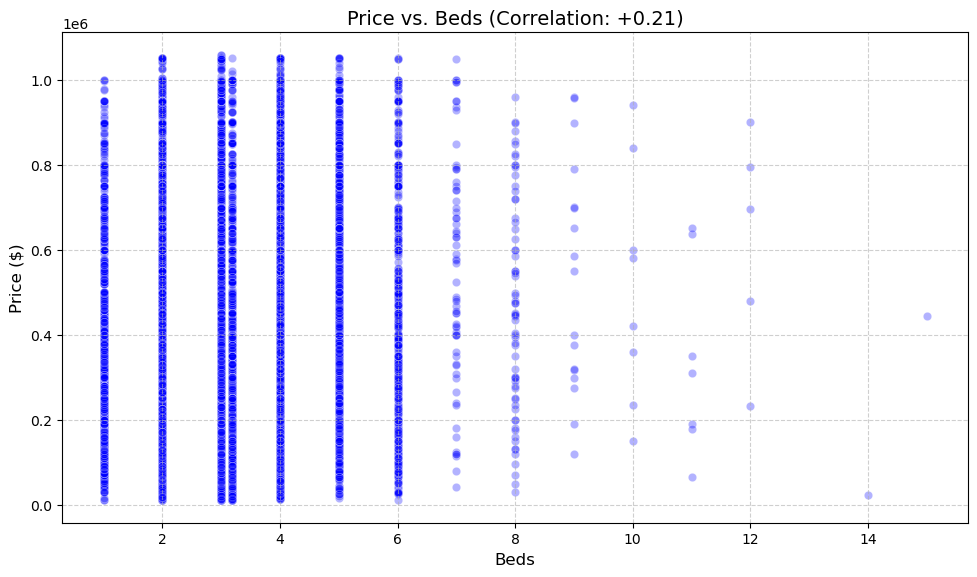

In [72]:
#plotting the relationship between price and number of bedrooms
plt.figure(figsize=(10, 6))
sns.scatterplot(data=housePrice_cleaned, x='Beds', y='Price', alpha=0.3, color='blue')

plt.title('Price vs. Beds (Correlation: +0.21)', fontsize=14)
plt.xlabel('Beds', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#saving the figure using the save_fig function
save_fig("price_vs_bath_scatter")
#displaying the plot
plt.show()

from visualizing the scatter plot between price and the number of bedrooms, I can conclude the relationship between Price and Bedrooms (+0.21) reveals a wide highly dispersed vertical spread. For instance, homes with 3 bedrooms span almost the entire price spectrum, visually confirming that bedroom count alone is too weak of a predictor to accurately price a home.

# More Data Cleaning

In [73]:
housePrice_More_cleaned = houseprice_filtered.copy()

In [74]:
#selectign a string and assigning it to the variable Sqr_Ft
Sqr_Ft = ['Sqr Ft']

#creating a function for applying IQR method to Sqr Ft
def apply_iqr_filter(housePrice_More_cleaned, Sqr_Ft):
    #removing Outliers using the IQR Method for Price. startign first by calculating the upper and lower Quartiles
    Q1 = housePrice_More_cleaned[Sqr_Ft].quantile(0.25)
    Q3 = housePrice_More_cleaned[Sqr_Ft].quantile(0.75)
    #calucating the Interquartile range
    IQR = Q3 - Q1
    
    #defining the bounds according to the standard statistical threshold (1.5 * IQR is the standard statistical threshold)
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    #returning a filtered data keeping only the rows within the bounds
    return housePrice_More_cleaned[(housePrice_More_cleaned[Sqr_Ft] >= lower_bound) & (housePrice_More_cleaned[Sqr_Ft] <= upper_bound)]

housePrice_More_cleaned = apply_iqr_filter(housePrice_More_cleaned, 'Sqr Ft')

#checing how many extreme outliers were removed
print(f"Original dataset rows: {len(houseprice_filtered)}")
print(f"Cleaned alternative dataset rows: {len(housePrice_More_cleaned)}")

Original dataset rows: 26933
Cleaned alternative dataset rows: 25932


I can see that after I have removed the outliners in the Sqr Ft column, now I can see that I have removed just over 1000 rows of outlines

In [75]:
#exporting the more cleaned filtered data to a new CSV file without the index column
housePrice_More_cleaned.to_csv("more_cleaned_filtered_houseprice.csv", index=False)

# Exploring the more cleaned data

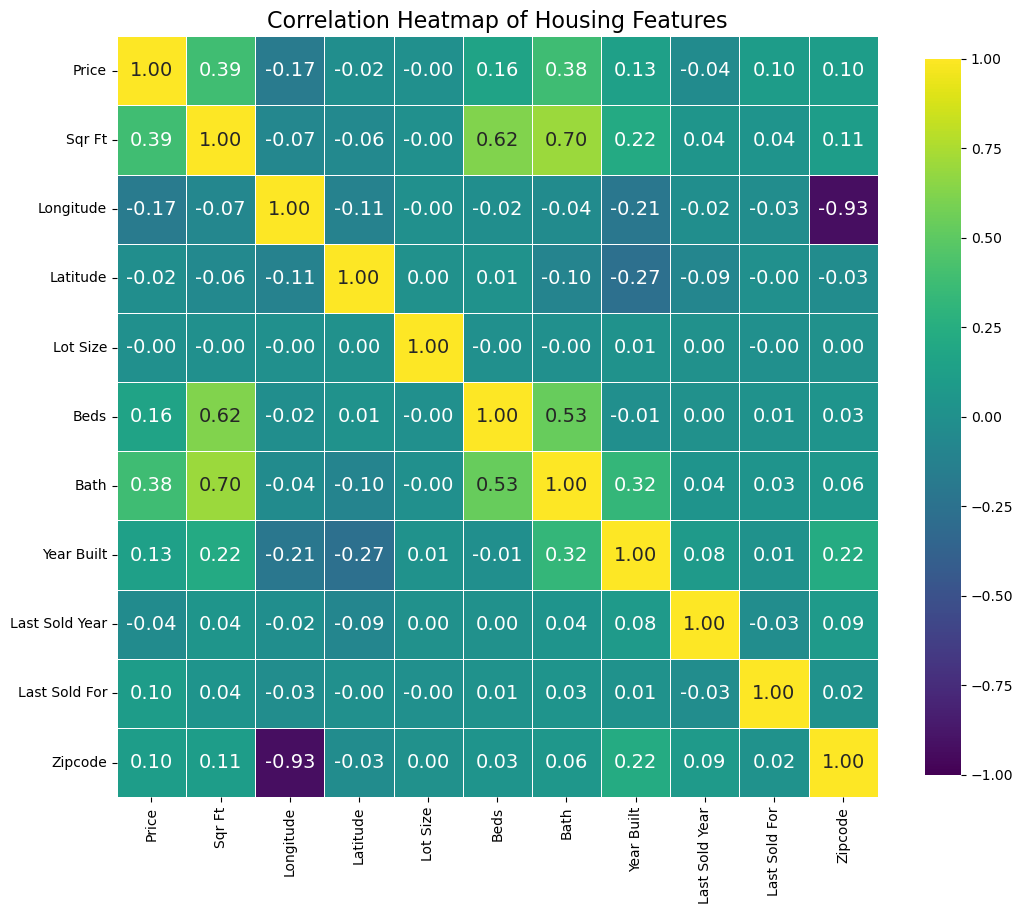

In [76]:
#selecting the numerical columns
numerical_cols = housePrice_More_cleaned.select_dtypes(include=[np.number]).columns

#calculating the correlation matrix
corr_matrix = housePrice_More_cleaned[numerical_cols].corr()

#creating a geometric mask to hide the top right triangle, and that's to remove duplicate data

#setting up the figure size
plt.figure(figsize=(11, 10))

#drawing the heatmap
sns.heatmap(corr_matrix, cmap='viridis', vmax=1.0, vmin=-1.0, center=0, square=True, linewidths=.5, annot=True, fmt='.2f', cbar_kws={"shrink": .8})

plt.title('Correlation Heatmap of Housing Features', fontsize=16)
#saving the figure using the save_fig function
save_fig("correlation_heatmap_filteredData")
#displaying the plot
plt.show()

### Looking at the price column on heatmap, I can see that:
#### Sqr Ft and price have a positive relationship +0.39, 
#### bath and price have a positive relationship +0.38, 
#### and price and beds have a positive relationship of +0.16, 
#### and price and year built have a positive relationship of +0.13, 
#### and price and longitude have a negative relationship of -0.17

Based on the correlation heatmap, I can understand that as the number of Sqr Ft goes up, the price is likely to go up. Also as the number of bathrooms goes up, the price is likely to go up. I can also see two other positive relationships and one negative that are not as strong as the house Sqr Ft and number of bathrooms, but still can help predict the house price, and those three predictors are the Longitude, numbers of beds, and the the year built of the house. so while the house Sqr Ft and the number of bathrooms is a solid indicator of a property's value, features like the Longitude, the year it was built, or the number of bedrooms are too inconsistent to predict price reliably on their own

## Scatter Plots

### Price and Sqr Ft

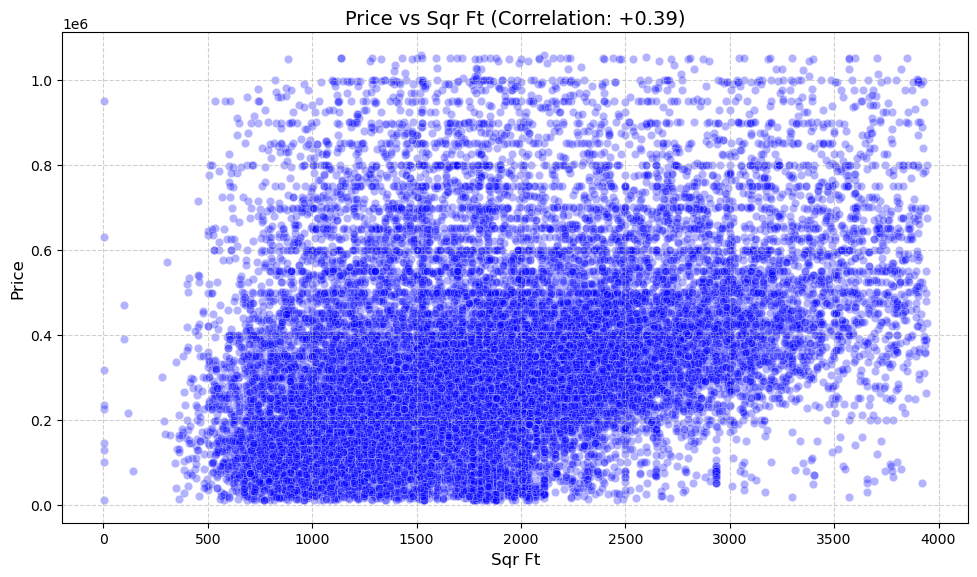

In [77]:
#plotting the relationship between price and square feet of the house
plt.figure(figsize=(10, 6))
#using alpha=0.3 to make the overlappin points darker, and that's to show density
sns.scatterplot(data=housePrice_More_cleaned, x='Sqr Ft', y='Price', alpha=0.3, color='blue')

plt.title('Price vs Sqr Ft (Correlation: +0.39)', fontsize=14)
plt.xlabel('Sqr Ft', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#saving the figure using the save_fig function
save_fig("price_vs_Sqr Ft_scatter")
#displaying the plot
plt.show()

### Price and Number of bathrooms

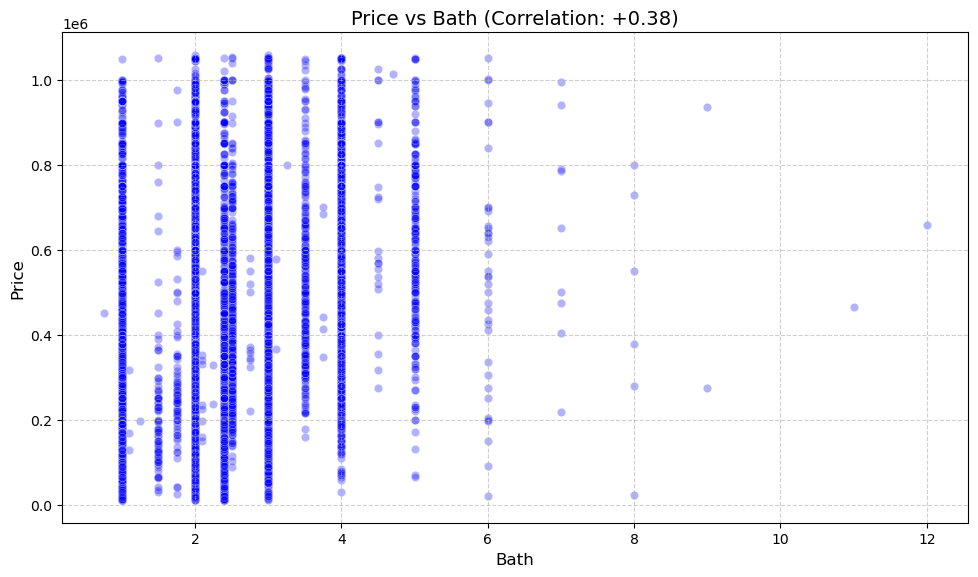

In [78]:
#plotting the relationship between price and number of bathrroms
plt.figure(figsize=(10, 6))
#using alpha=0.3 to make the overlappin points darker, and that's to show density
sns.scatterplot(data=housePrice_More_cleaned, x='Bath', y='Price', alpha=0.3, color='blue')

plt.title('Price vs Bath (Correlation: +0.38)', fontsize=14)
plt.xlabel('Bath', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#saving the figure using the save_fig function
save_fig("price_vs_bath_scatter")
#displaying the plot
plt.show()

# Data Splitting

#### Splitting the cleaned data into training data and testing data

In [79]:
#I will be separating the target column Price from the rest of the columns, since the Price column is what I want to predict, so I am assigning the price column to the variable y_Price
y1_Price = housePrice_cleaned['Price']

#adding a list of strings to the variable columns, and each of one of these strings represent a columnName 
Predictors1 = ['Sqr Ft', 'Lot Size', 'Beds', 'Bath', 'Year Built', 'Last Sold Year', 'Last Sold For', 'Longitude', 'Latitude', 'Zipcode']

#assigning the the columns in the variable Predictors to the variable 'X_Predictors', and this variable represents all the predicators that can afffect the house price
X1_Predictors = housePrice_cleaned[Predictors1]

#assigning 20% of the data for testing
X1_temp, X1_test, y1_temp, y1_test = train_test_split(X1_Predictors, y1_Price, test_size=0.20, random_state=42)

#thne assigning 20% of the remaining data for validation
X1_train, X1_val, y1_train, y1_val = train_test_split(X1_temp, y1_temp, test_size=0.20, random_state=42)

#printing the outcome of data splitting
print(f"Total original houses: {len(housePrice_cleaned)}")
print(f"Training set (60%): {len(X1_train)} houses")
print(f"Validation set (20%): {len(X1_val)} houses")
print(f"Testing set (20%): {len(X1_test)} houses")

Total original houses: 26933
Training set (60%): 17236 houses
Validation set (20%): 4310 houses
Testing set (20%): 5387 houses


I can see that the 20% for validation has less number of houses than the 20% for testing, and that's because the 20% for testing was 20% out of 100%, while the 20% of validation was done was data has been already taken out for testing. so the validation took 20% out of the remaining 80% of the data

### Splitting the more cleaned data into training data and testing data

In [80]:
#I will be separating the target column Price from the rest of the columns, since the Price column is what I want to predict, so I am assigning the price column to the variable y_Price
y2_Price = housePrice_More_cleaned['Price']

#adding a list of strings to the variable columns, and each of one of these strings represent a columnName 
Predictors2 = ['Sqr Ft', 'Lot Size', 'Beds', 'Bath', 'Year Built', 'Last Sold Year', 'Last Sold For', 'Longitude', 'Latitude', 'Zipcode']

#assigning the the columns in the variable Predictors to the variable 'X_Predictors', and this variable represents all the predicators that can afffect the house price
X2_Predictors = housePrice_More_cleaned[Predictors2]

#assigning 20% of the data for testing
X2_temp, X2_test, y2_temp, y2_test = train_test_split(X2_Predictors, y2_Price, test_size=0.20, random_state=42)

#thne assigning 20% of the remaining data for validation
X2_train, X2_val, y2_train, y2_val = train_test_split(X2_temp, y2_temp, test_size=0.20, random_state=42)

#printing the outcome of data splitting
print(f"Total original houses: {len(housePrice_More_cleaned)}")
print(f"Training set (60%): {len(X2_train)} houses")
print(f"Validation set (20%): {len(X2_val)} houses")
print(f"Testing set (20%): {len(X2_test)} houses")

Total original houses: 25932
Training set (60%): 16596 houses
Validation set (20%): 4149 houses
Testing set (20%): 5187 houses


I can see that the 20% for validation has less number of houses than the 20% for testing, and that's because the 20% for testing was 20% out of 100%, while the 20% of validation was done was data has been already taken out for testing. so the validation took 20% out of the remaining 80% of the data

# Linear Regression

##### Linear regression attempts to predict house prices by modelling a linear relationship between the input features and the target value.

In [81]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

### Training the linear regression model on the my_cleaned_filtered_houseprice.csv

In [82]:
#creating a linear regression model
model1 = LinearRegression()

#training the model
model1.fit(X1_train, y1_train) #using .fit() to tell the model to look at the housePrice_predictors in the training data (X1_train), and then asking the model to learn how these predictors resulted in the housePrices in the training data (y1_train)
print("The model has successfully learned from the training data!")

#evaluating and validating the model using the validation data
val1_predictions = model1.predict(X1_val) #using .predict() to give the model the housePrice_predictors in the validation data (X1_val), which the model hasn't yet seen. Then we ask the model to predict the housePrice

#comparing the model housePrices guesses (val1_predictions) to the real answers in the validation data (y1_val)
r2_model1 = r2_score(y1_val, val1_predictions) 
mae_model1 = mean_absolute_error(y1_val, val1_predictions)

print(f"Validation R-squared Score: {r2_model1:.2f}")
print(f"Validation Mean Absolute Error: ${mae_model1:,.2f}")

The model has successfully learned from the training data!
Validation R-squared Score: -13.80
Validation Mean Absolute Error: $142,360.96


### Training a second linear regression model on the more_cleaned_filtered_houseprice.csv

In [83]:
#creating a linear regression model
model2 = LinearRegression()

#training the model
model2.fit(X2_train, y2_train) #using .fit() to tell the model to look at the housePrice_predictors in the training data (X2_train), and then asking the model to learn how these predictors resulted in the housePrices in the training data (y2_train)
print("The model has successfully learned from the training data!")

#evaluating and validating the model using the validation data
val2_predictions = model2.predict(X2_val) #using .predict() to give the model the housePrice_predictors in the validation data (X2_val), which the model hasn't yet seen, and then asking the model to predict the housePrice

#comparing the model housePrices guesses (val2_predictions) to the real answers in the validation data (y2_val)
r2_model2 = r2_score(y2_val, val2_predictions) 
mae_model2 = mean_absolute_error(y2_val, val2_predictions)

print(f"Validation R-squared Score: {r2_model2:.2f}")
print(f"Validation Mean Absolute Error: ${mae_model2:,.2f}")

The model has successfully learned from the training data!
Validation R-squared Score: 0.27
Validation Mean Absolute Error: $134,677.73


comparing the results from the two models, I can see the second model has an improved Validation Mean Absolute Error ($134,677.73) when compared to the first model ($142,360.96), so I can conclude that after cleaning the data, the model's pricing accuracy has improved by nearly $8,000 per house, and the model is better at predicting the houseprice after the data was cleaned and outlier was removed.

while comparing the results from the two models, I can also conclude the outliers of the house square feet column have had a huge on the model ability to predict the right house price, and that according to the R-squared Score. The score of the first model is (-13.7960), and the score the score of second model is (0.2713). So I can conclude that initially, extreme outlier properties confused the pricing algorithm of the model, causing the model to perform worse than just guessing the average price for every house. However, by removing those abnormal properties in the more_cleaned data, the model explains about 27% of a house's value using the basic features like house square feet(which represents the size of the house), bathrooms count, and bedroom count. This tells the business that while house size is important, the remaining 73% of a house's value is driven by other factors, such as curb appeal, school districts, or neighborhood desirability.

# Random Forest Regressor

##### Random Forest is a more advanced machine learning algorithm that combines multiple decision trees to improve prediction accuracy.

In [84]:
from sklearn.ensemble import RandomForestRegressor

### Training the Random Forest Regressor model on the my_cleaned_filtered_houseprice.csv

In [85]:
#creating a Random Forest Regressor model
rf_model1 = RandomForestRegressor(random_state=42)

#training the model
rf_model1.fit(X1_train, y1_train) #using .fit() to tell the model to look at the housePrice_predictors in the training data (X1_train), and then asking the model to learn how these predictors resulted in the housePrices in the training data (y1_train)

#evaluating and validating the model using the validation data
rf_val_predictions1 = rf_model1.predict(X1_val) #using .predict() to give the model the housePrice_predictors in the validation data (X1_val), which the model hasn't yet seen, and then asking the model to predict the housePrice

#comparing the model housePrices guesses (rf_val_predictions1) to the real answers in the validation data (y1_val)
rf_r2_model1 = r2_score(y1_val, rf_val_predictions1)
rf_mae_model1 = mean_absolute_error(y1_val, rf_val_predictions1)

print(f"Validation R-squared Score: {rf_r2_model1:.2f}")
print(f"Validation Mean Absolute Error: ${rf_mae_model1:,.2f}")

Validation R-squared Score: 0.73
Validation Mean Absolute Error: $76,090.77


### Training a second Random Forest Regressor model on the more_cleaned_filtered_houseprice.csv

In [86]:
#creating a Random Forest Regressor model
rf_model2 = RandomForestRegressor(random_state=42)

#training the model
rf_model2.fit(X2_train, y2_train) #using .fit() to tell the model to look at the housePrice_predictors in the training data (X2_train), and then asking the model to learn how these predictors resulted in the housePrices in the training data (y2_train)

#evaluating and validating the model using the validation data
rf_val_predictions2 = rf_model2.predict(X2_val) #using .predict() to give the model the housePrice_predictors in the validation data (X2_val), which the model hasn't yet seen, and then asking the model to predict the housePrice

#comparing the model housePrices guesses (rf_val_predictions2) to the real answers in the validation data (y2_val)
rf_r2_model2 = r2_score(y2_val, rf_val_predictions2)
rf_mae_model2 = mean_absolute_error(y2_val, rf_val_predictions2)

print(f"Validation R-squared Score: {rf_r2_model2:.2f}")
print(f"Validation Mean Absolute Error: ${rf_mae_model2:,.2f}")

Validation R-squared Score: 0.73
Validation Mean Absolute Error: $73,829.31


Looking at the two Random Forest Regressor, I can see the second model has an improved Validation Mean Absolute Error ($73,829.31) when compared to the first model ($76,090.77), so I can conclude that after cleaning the data, the model's pricing accuracy has improved by nearly $2,200 per house, and the model is better at predicting the houseprice after the data was cleaned and outlier was removed.

Looking at the two machine learing algorithms I used, the linear regression and the Random Forest Regressor, I can say that while the regression model explained about 27% of a house's value, the Random Forest Regressor is more accurate as it is able to explain about 73% of the house's value, using the basic features like house square feet(which represents the size of the house), bathrooms count, and bedroom count. I can conclude that the Random Forest Regressor model is more accurate at predicting the house's value than the linear regression model.

## Feature Importance

In [87]:
#storing the feature scores in the variable importances
importances = rf_model2.feature_importances_

for score, name in zip(importances, X2_train.columns):
    print(round(score, 2), name)

0.11 Sqr Ft
0.06 Lot Size
0.02 Beds
0.12 Bath
0.06 Year Built
0.02 Last Sold Year
0.28 Last Sold For
0.15 Longitude
0.09 Latitude
0.09 Zipcode


The important features for this Random Forest Regressor model are 0.28 Last Sold For, 0.15 Longitude, 0.12 Bath, and 0.11 Sqr Ft

# Testing the best regression model

In [88]:
#testing the model using the test data
final_predictions = rf_model2.predict(X2_test)

#comparing the model housePrices guesses (final_predictions) to the real answers in the validation data (y2_test)
final_r2 = r2_score(y2_test, final_predictions)
final_mae = mean_absolute_error(y2_test, final_predictions)

print(f"Final Test R-squared Score: {final_r2:.2f}")
print(f"Final Test Mean Absolute Error: ${final_mae:,.2f}")

Final Test R-squared Score: 0.74
Final Test Mean Absolute Error: $71,965.13


# Clustering

##### clustering is an unsupervised machine learning technique

In [89]:
from sklearn.cluster import KMeans

#creating a copy of the data for clustering
housePrice_cluster = housePrice_More_cleaned.copy()

In [90]:
#exporting the copy of the dataset that I created for clustering to a new CSV file without the index column
housePrice_cluster.to_csv("housePrice_cluster.csv", index=False)

In [91]:
#turning the price column into a 2D array
price_cluster = housePrice_cluster[['Price']]

### Elbow Method

Using the elbow method to find the Optimal Number of Price Teams

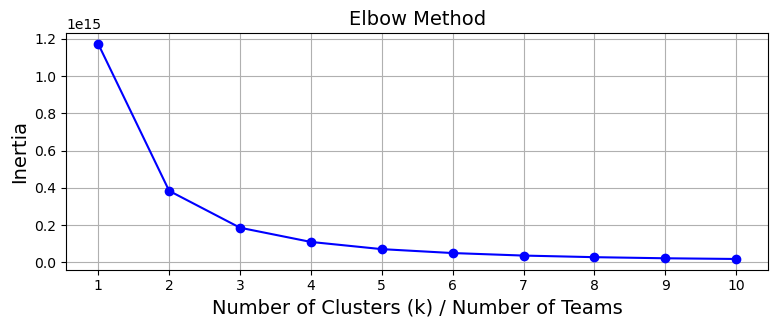

In [92]:
#initializing a list to store the interia values of each model
Inertias = []
#starting a range from 1 to 10, and storing that range in the variable k_values to test what would be the best number of teams ranging from 1 team to 10 teams
k_values = range(1, 11)

for k in k_values:
        #the number of clusters changes after each loop, looping from number of clusters 1 to 10 clusters
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10);
        #training the model
        kmeans.fit(price_cluster)
        #adding the interia value to the list. Interia is the distance btw houses and their cluster center
        Inertias.append(kmeans.inertia_)
    
#plotting the elbow curve
plt.figure(figsize=(8, 3.5))
plt.title('Elbow Method')
plt.plot(k_values, Inertias, "bo-")
plt.xlabel('Number of Clusters (k) / Number of Teams')
plt.xticks(k_values)
plt.ylabel('Inertia')
plt.grid()
save_fig("cluster_elbow_method")
plt.show()


By visiualy analysing the elbow method graph, I can sayy that number of cluster = 3 is the optimal number of teams. So the client should consider creating three specialised teams for houses at different price categories: luxury, affordable, budget

### Silhouette Score

calculating a silhouette score to determine the best number of teams from 2 teams to 10 teams

In [93]:
from sklearn.metrics import silhouette_score

In [94]:
#initializing a list to store the silhouette scores of each model
silhouette_scores = []

#starting a range from 2 to 10, and storing that range in the variable k_values_sil to test what would be the best number of teams ranging from 2 to 10 teams
k_values_sil = range(2, 11)

for k in k_values_sil:
    #the number of clusters changes after each loop, looping from number of clusters 1 to 10 clusters
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    #training the model
    kmeans = kmeans.fit(price_cluster)
    #calculate the score for each value of k, and storing it in the variable score
    score = silhouette_score(price_cluster, kmeans.labels_)
    #adding the score value to the list of silhouette scores
    silhouette_scores.append(score)
    #displaying the scores
    print(f"{k} teams has a Score of: {score:.2f}")

#using the function argmax() returns the index with the highest silhouette_score
best_index = np.argmax(silhouette_scores)
#finding the number of teams with the index number that we identified that it has the highest silhouette_score
best_k = k_values_sil[best_index]

print(f"The number of teams with the highest silhouette_score is {best_k}")

2 teams has a Score of: 0.63
3 teams has a Score of: 0.56
4 teams has a Score of: 0.54
5 teams has a Score of: 0.54
6 teams has a Score of: 0.53
7 teams has a Score of: 0.54
8 teams has a Score of: 0.54
9 teams has a Score of: 0.54
10 teams has a Score of: 0.54
The number of teams with the highest silhouette_score is 2


According to the silhouette scores, the best number of teams is 2 teams

Now I have evaluated the best number of teams through two methods, the elbow method and silhouette score method, to find the best number of clusters. While the elbow method showed an elbow bend when the number of clusters is 3, the silhouette score method suggests that having 2 teams is favored for having the highest silhouette score. While 2 teams is mathematicaly the safest way to split the team, having three teams at different price categories of Budget, Standard, and Luxury teams might be much more practical for the business operations. A three specialised teams for houses allows agents to specialize more deeply without overly fragmenting the market.

# Creating Dataset with 3 categories for classification

#### creating a dataset with 3 categories that represent the type of the house, and creating a column for the categorical type of the house, and removing the price from this dataset

In [95]:
#creating a copy of the data 
three_clusters = housePrice_cluster.copy()
#kmeans with 3 clusterss
final_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
#fitting and calculatin the clusters as the algorithm is tryin to figuure out where is the exacat center of each price tier should be, and then predicting and assigning a label from the three labels that represent the clusters 0, 1, or 2, annd assigning a label to every single house row in the dataset in the CSV file. price_cluster representts the price column
category_labels = final_kmeans.fit_predict(price_cluster) 

#adding a column that contains the categories off each house to the dataset in the CSV file
three_clusters['house_Category'] = category_labels
#adding meaningful names to the label, so the label would represent if the house is a budget house or a standard house, or a luxury house
three_clusters['house_Category'] = three_clusters['house_Category'].replace({ 0: 'Budget', 1: 'Standard', 2: 'Luxury' })
#removing the price column from the dataset
three_clusters = three_clusters.drop(columns=['Price'])

In [96]:
#explorating the new dataset by displaying some of the columns in the new dataset
three_clusters[['Address', 'Beds', 'Sqr Ft', 'house_Category']].head()

,Address,Beds,Sqr Ft,house_Category
0,"630 W Echo Ln Phoenix, AZ 85021",4.000000,3447.0,Luxury
1,"2367 Highwood Dr Dallas, TX 75228",3.000000,1767.0,Budget
2,"30 Hurlock Ave Buffalo, NY 14211",3.000000,1232.0,Budget
3,"6416 Alderton St Flushing, NY 11374",3.000000,1417.0,Luxury
4,"251 NW 177th St #A-123 Miami Gardens, FL 33169",3.188282,440.0,Budget


In [99]:
#exporting the copy of the dataset for classification to a new CSV file without the index column
three_clusters.to_csv("three_clusters.csv", index=False)

# Summary

### Project Overview

#### I was tasked with developing a machine learning model capable of accurately predicting house prices. Before modeling, I started by exploring the data and cleaning the data. Exploring the data helped identify the need for removing outliers to prevent skewed predictions. For example the outliers for the square feet has been removed in the data cleaning phase. Furthermore, land measurements were standardized, converting mixed "acre" entries into uniform "square foot" to ensure the algorithms could accurately assess land value.

### Machine Learning Performance

#### I started by splitting the data into training, validation, and test sets. Then I trained the model using the linear regression alogorithm and the random forest regressor algorithm, and the compared their outcomes

#### The Random Forest Regressor significantly outperformed the linear regression model. When Random Forest Regressor was evaluated on the final, unseen Test Set (simulating real-world market conditions), the model achieved:
##### Accuracy (R-Squared): 74% success in explaining house's value, using the basic features like house square feet
##### Average Error (MAE): When pricing a new home, the model's prediction is, on average, within $71,965 of the true market selling price.

# Client Advise

#### The other information (not included in the dataset) may further improve the model performance are knowing the property condition, renovation history, mortgage rate, and neighborhood school ratings

# screenshots project management 

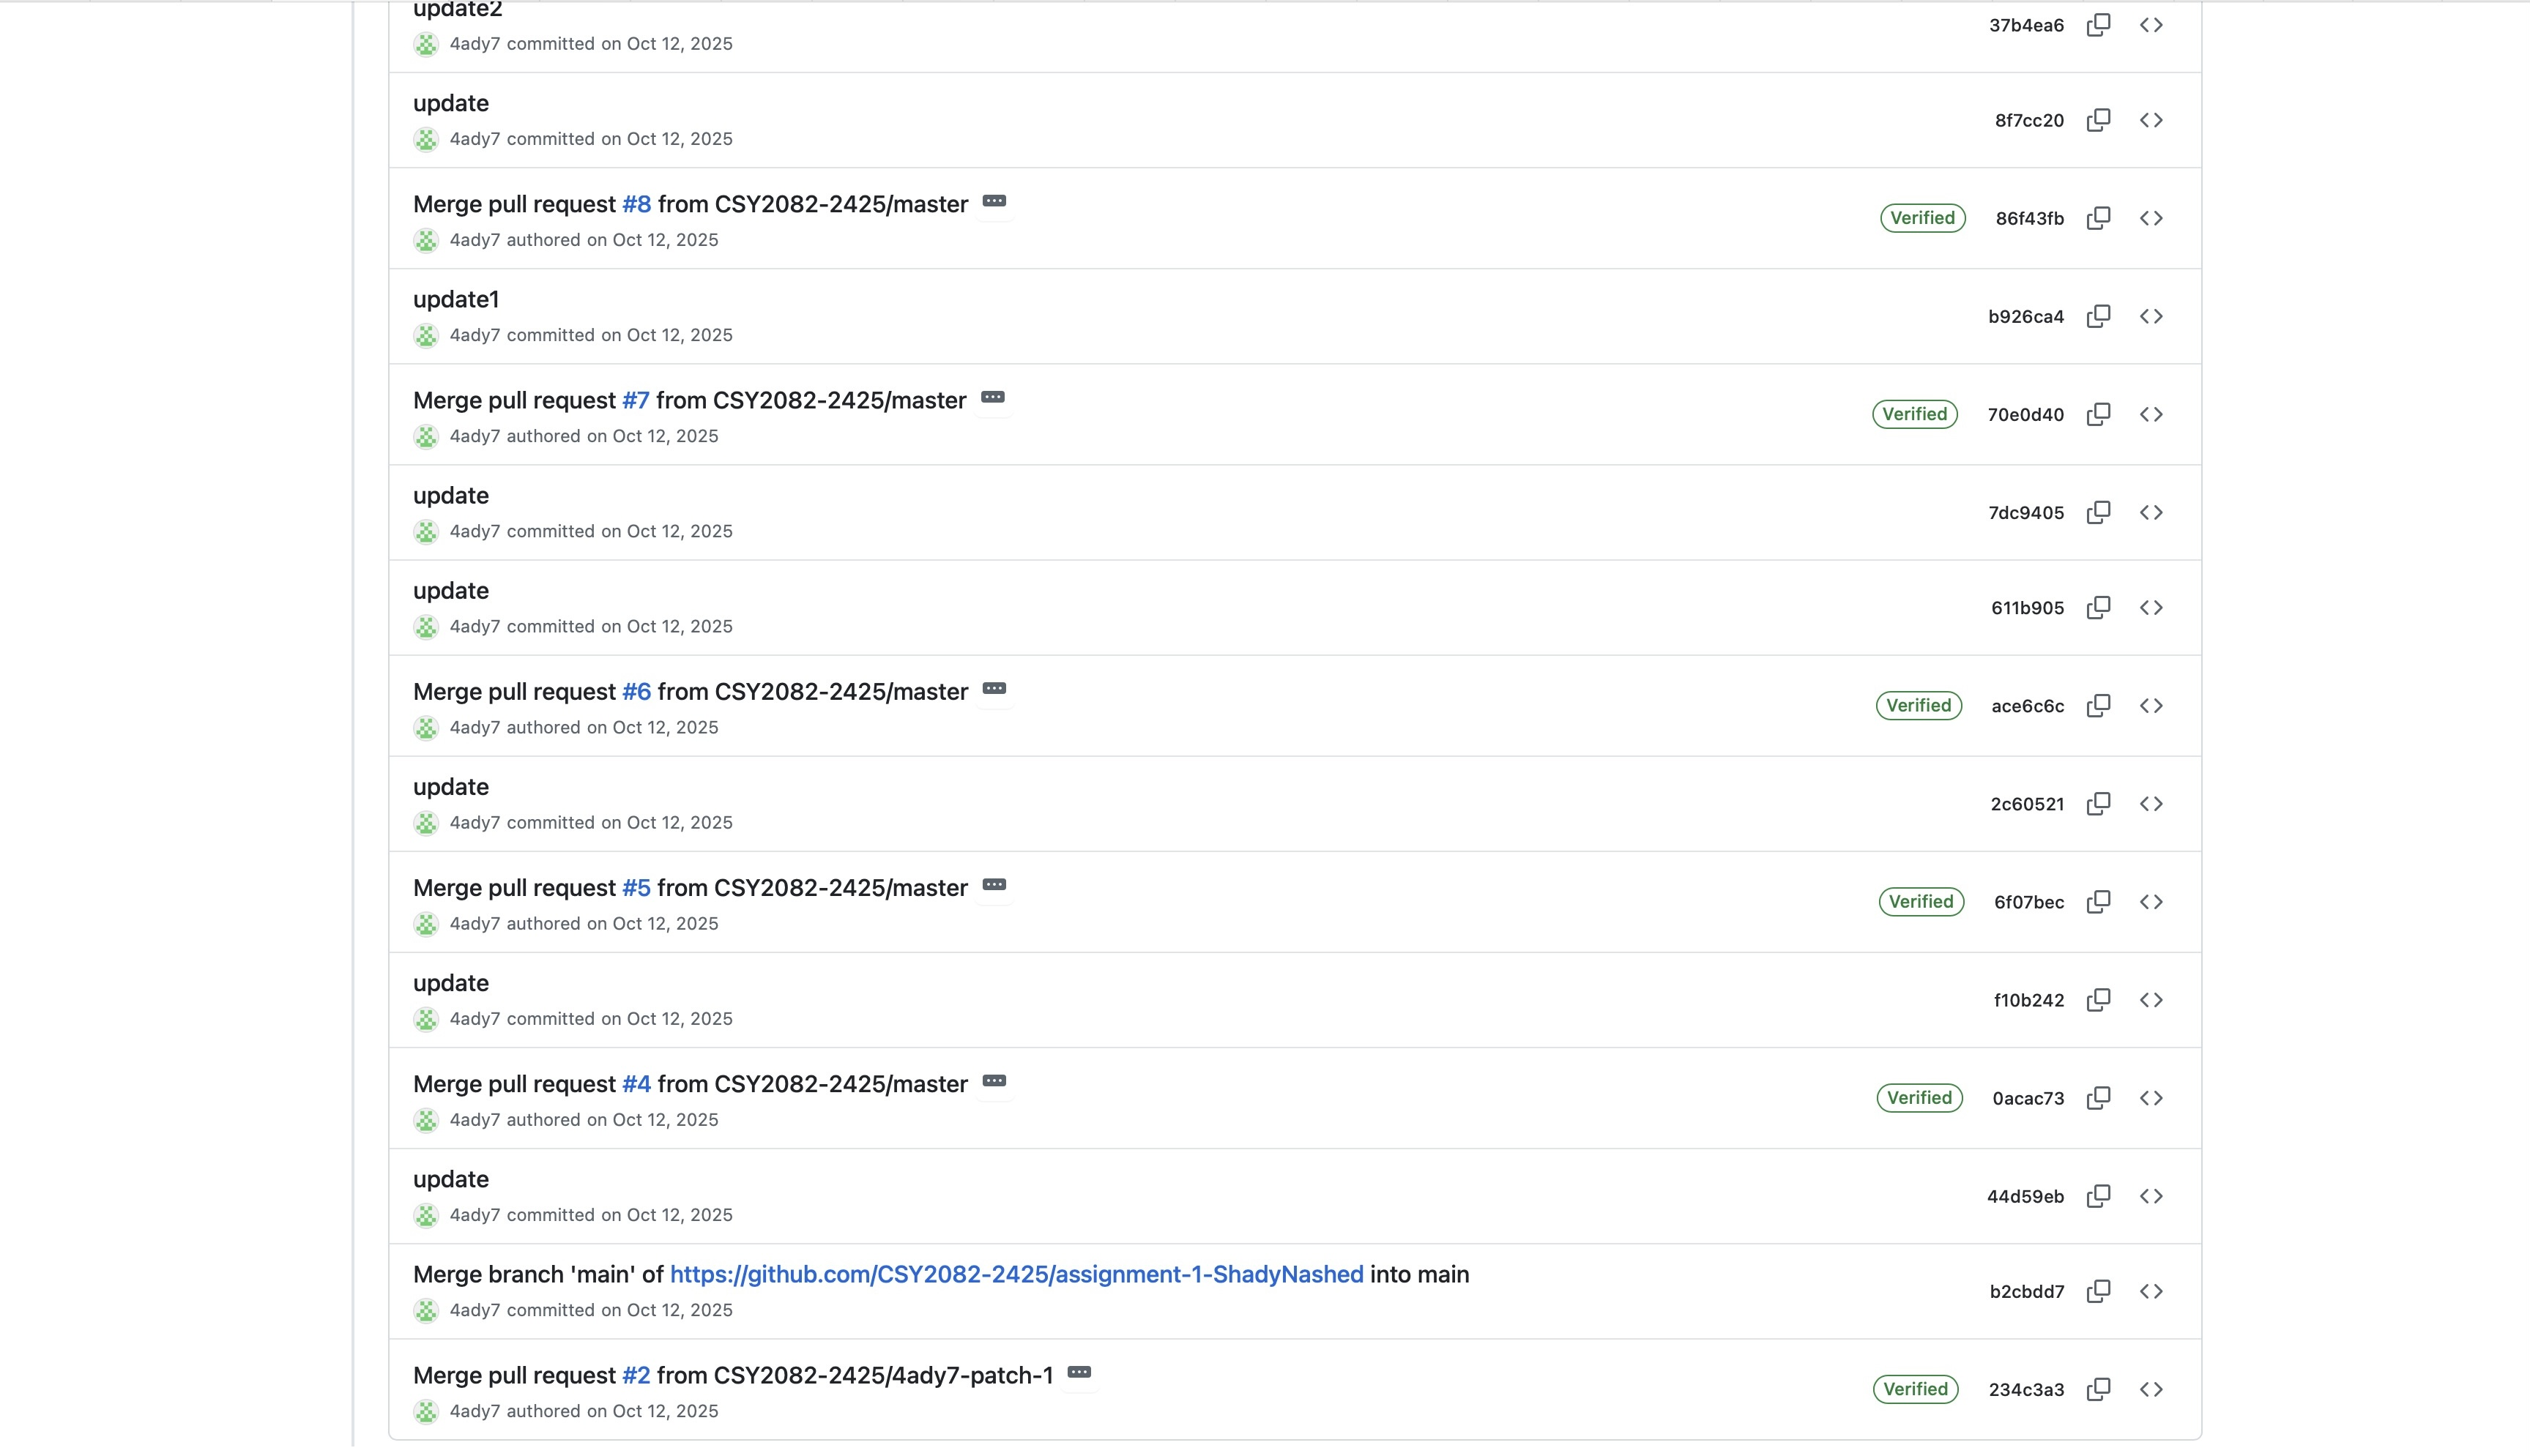

In [97]:
from IPython.display import Image, display

img_path = Path()/"Commits"/"1stCommit.jpeg"

display(Image(filename=img_path))

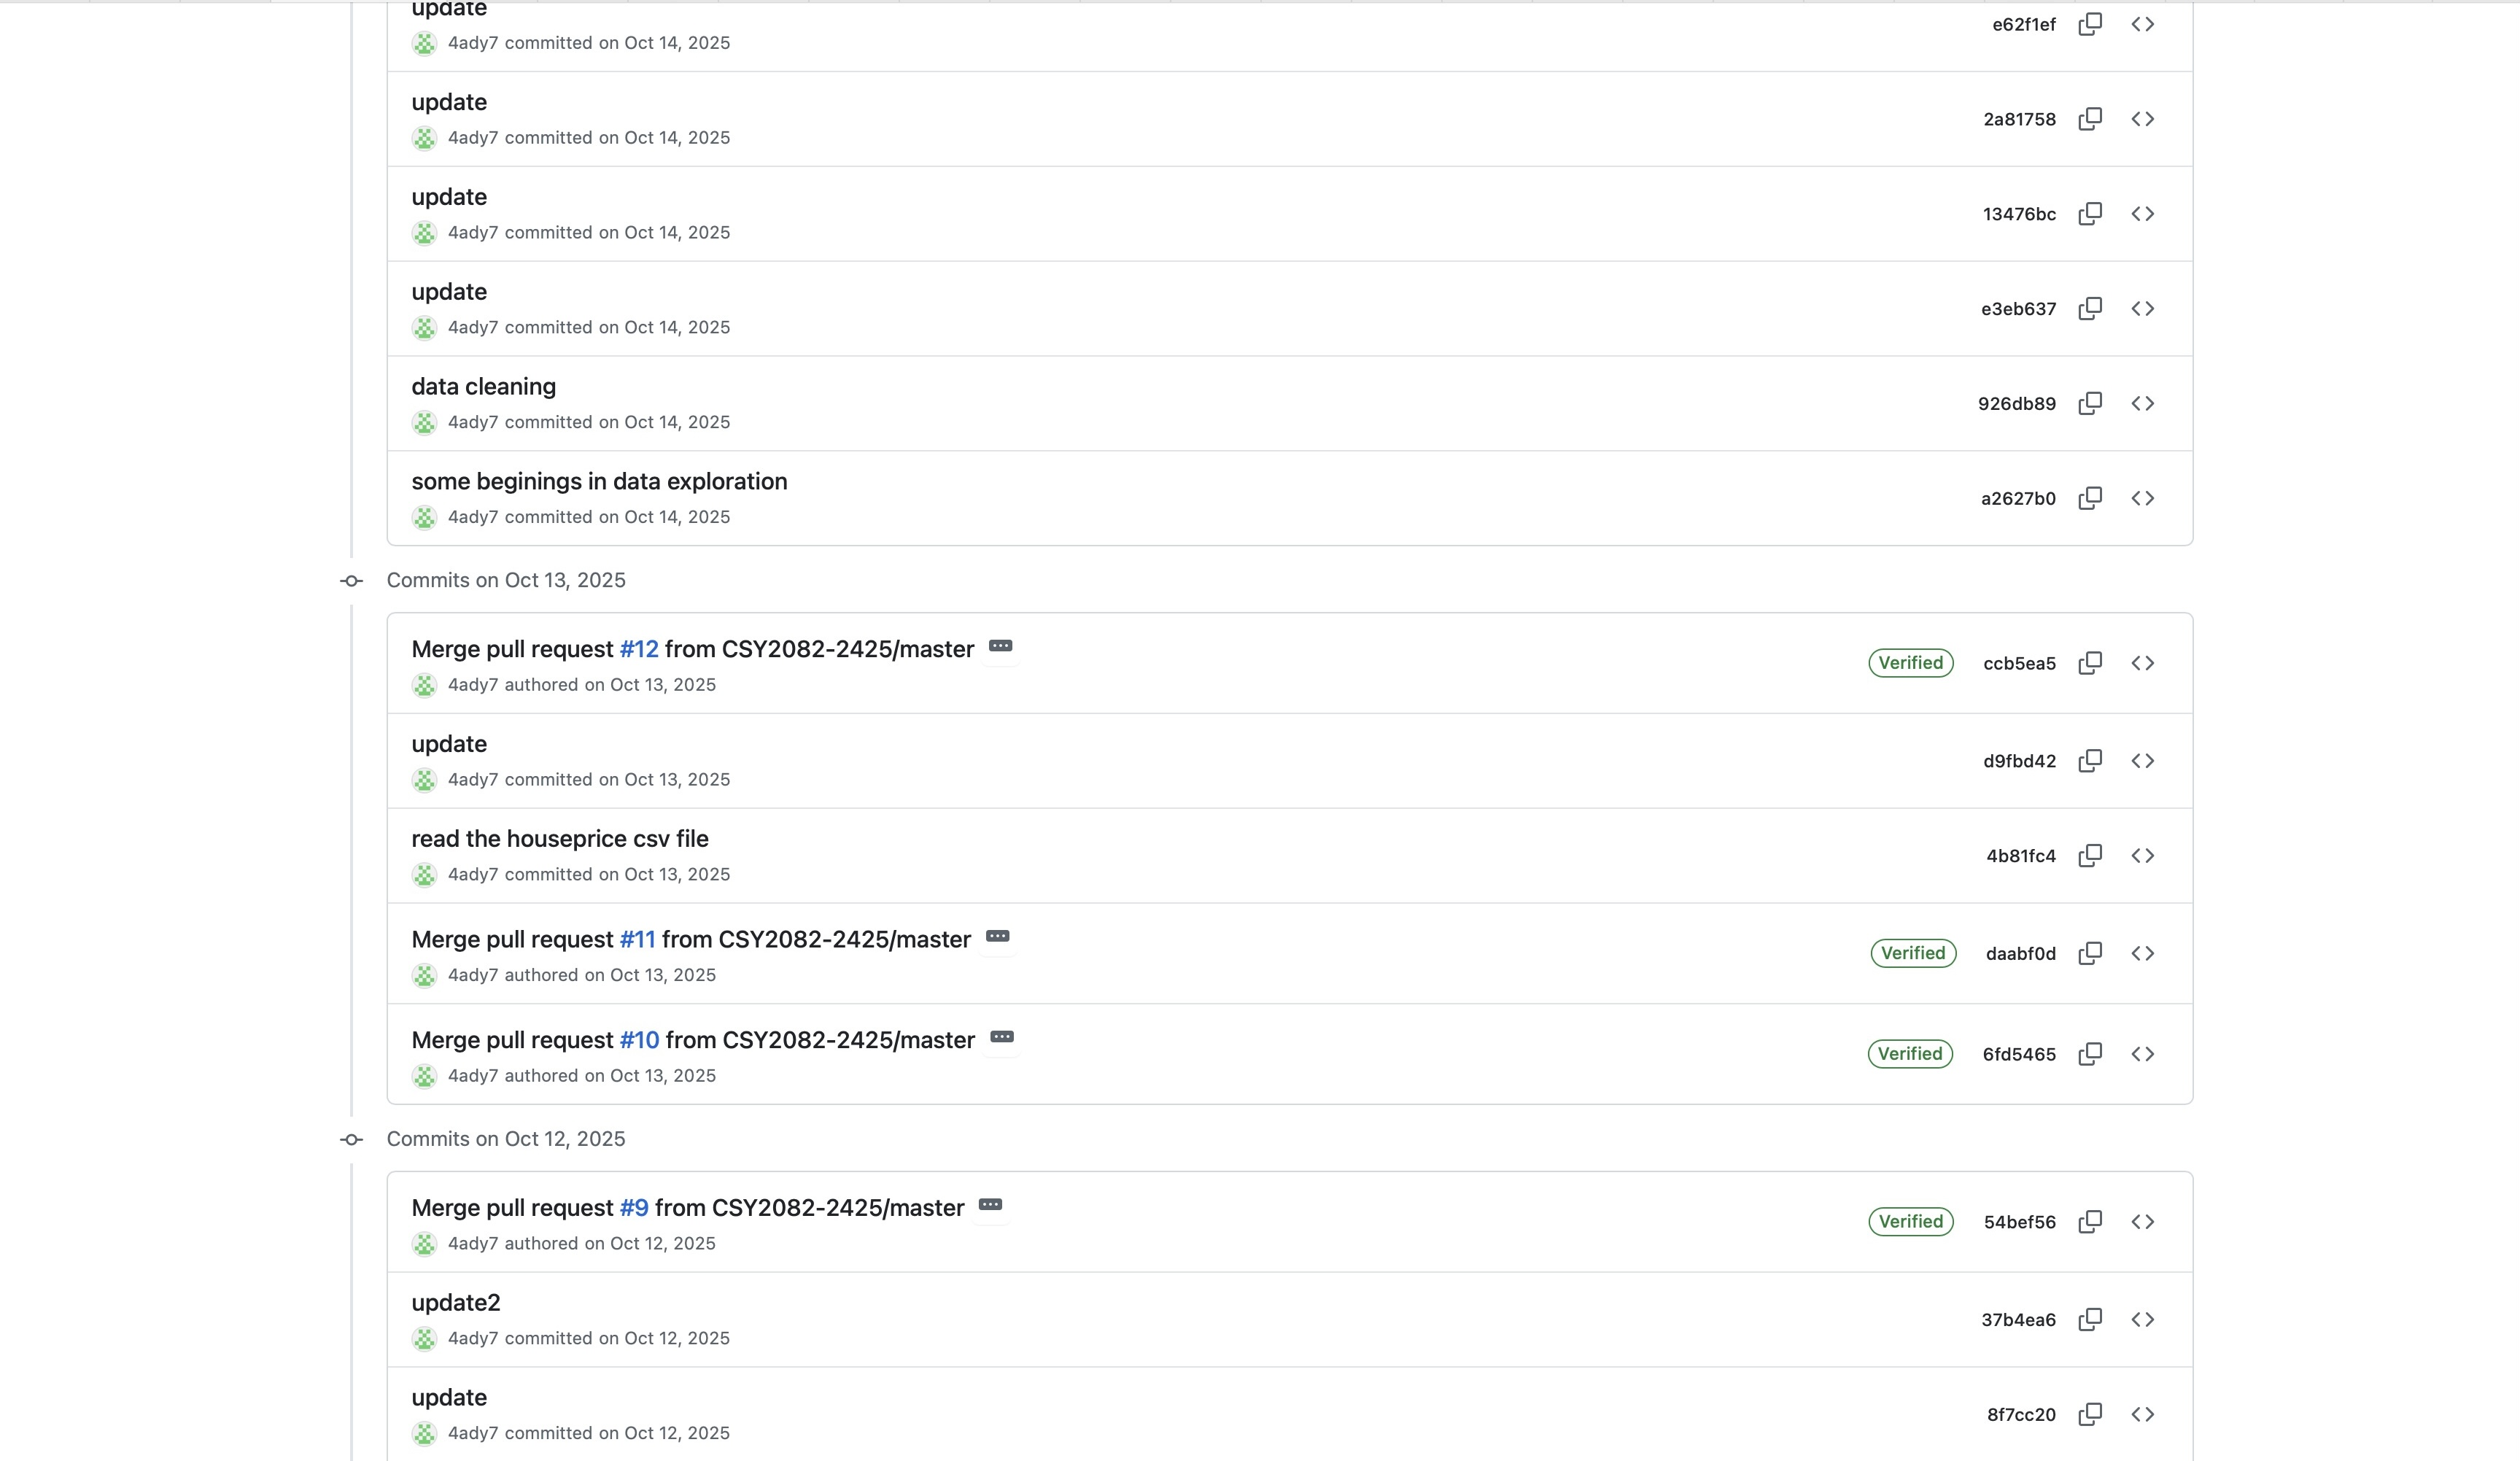

In [98]:
img_path = Path()/"Commits"/"2ndCommit.jpeg"

display(Image(filename=img_path))